In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    accuracy_score
)

In [3]:
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [4]:
df['target'] = (df['target'] == 0).astype(int)
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum().sum())
print("\nTarget distribution:")
print(df['target'].value_counts())
print("\nTarget labels:")
print("0 = Benign")
print("1 = Malignant")

Dataset shape: (569, 31)

Missing values:
0

Target distribution:
target
0    357
1    212
Name: count, dtype: int64

Target labels:
0 = Benign
1 = Malignant


In [5]:
X = df.drop('target', axis=1)
y = df['target']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (569, 30)
Target shape: (569,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [9]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
model = LogisticRegression(max_iter=10000, random_state=42)

model.fit(X_train_scaled, y_train)

print("Model training completed successfully!")
X_test_scaled = scaler.transform(X_test)

Model training completed successfully!


In [10]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print("First 10 actual values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted values:")
print(y_pred[:10])

print("\nFirst 10 predicted probabilities:")
print(y_prob[:10])

First 10 actual values:
[0 1 0 1 0 0 1 0 0 0]

First 10 predicted values:
[0 1 0 1 1 0 1 0 0 0]

First 10 predicted probabilities:
[3.64568116e-04 9.99999989e-01 4.25679471e-02 5.76187322e-01
 5.09155489e-01 6.16001620e-04 7.61534086e-01 1.01217174e-03
 5.68725516e-04 1.07675795e-02]


In [11]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))

Accuracy: 0.9649
Precision: 0.975
Recall: 0.9286


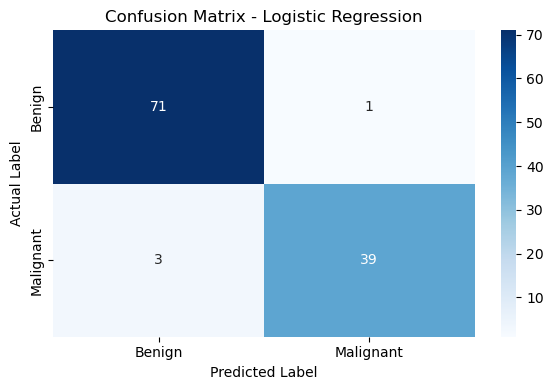

In [12]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix - Logistic Regression')

plt.tight_layout()
plt.show()

In [13]:
print(classification_report(
    y_test,
    y_pred,
    target_names=['Benign', 'Malignant']
))

              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



In [14]:
roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", round(roc_auc, 4))

ROC-AUC Score: 0.996


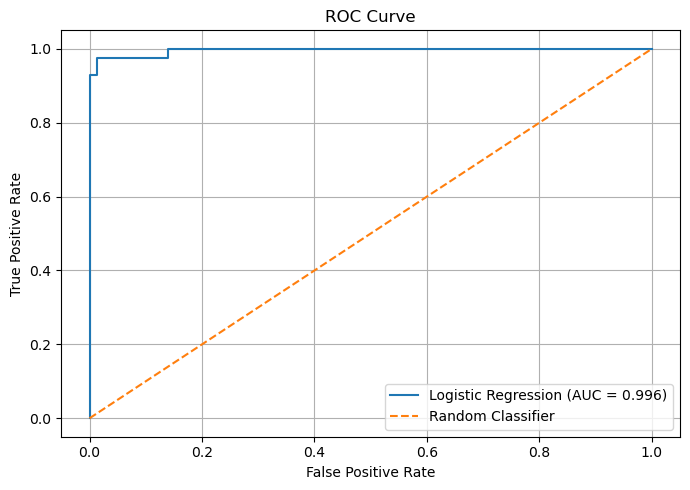

In [15]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure(figsize=(7, 5))
plt.plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {roc_auc:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
threshold = 0.30
y_pred_custom = (y_prob >= threshold).astype(int)
custom_precision = precision_score(
    y_test,
    y_pred_custom,
    zero_division=0
)

custom_recall = recall_score(
    y_test,
    y_pred_custom,
    zero_division=0
)

print("Threshold:", threshold)
print("Precision:", round(custom_precision, 4))
print("Recall:", round(custom_recall, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_custom))

Threshold: 0.3
Precision: 0.9762
Recall: 0.9762

Confusion Matrix:
[[71  1]
 [ 1 41]]


In [18]:
thresholds_to_test = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

results = []

for threshold in thresholds_to_test:

    y_pred_threshold = (y_prob >= threshold).astype(int)

    precision = precision_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    results.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall
    })

results_df = pd.DataFrame(results)

results_df.round(3)

,Threshold,Precision,Recall
0,0.2,0.911,0.976
1,0.3,0.976,0.976
2,0.4,0.976,0.952
3,0.5,0.975,0.929
4,0.6,1.000,0.905
5,0.7,1.000,0.905


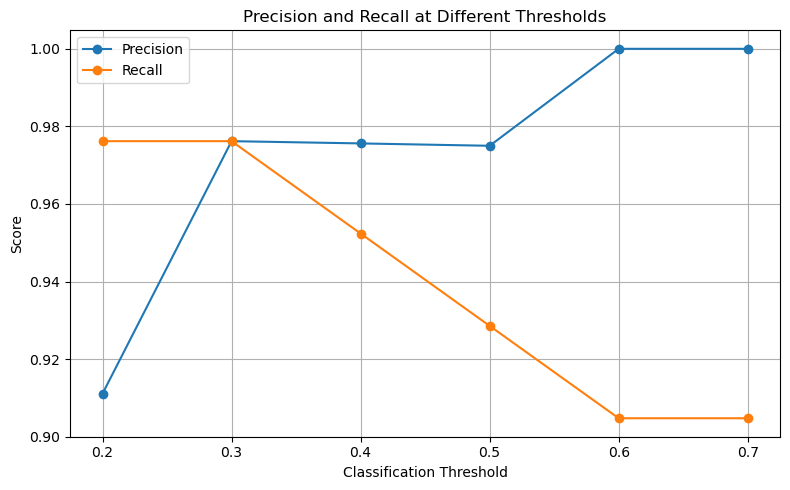

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df['Threshold'],
    results_df['Precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    results_df['Threshold'],
    results_df['Recall'],
    marker='o',
    label='Recall'
)

plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall at Different Thresholds')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [20]:
print("=" * 45)
print("BREAST CANCER PREDICTION")
print("=" * 45)

print("Algorithm: Logistic Regression")
print("Dataset: Breast Cancer Wisconsin")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nModel Performance")
print("-" * 45)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\nConfusion Matrix:")
print(cm)

print("=" * 45)

BREAST CANCER PREDICTION
Algorithm: Logistic Regression
Dataset: Breast Cancer Wisconsin
Training samples: 455
Testing samples: 114

Model Performance
---------------------------------------------
Accuracy : 0.9649
Precision: 0.9750
Recall   : 0.9286
ROC-AUC  : 0.9960

Confusion Matrix:
[[71  1]
 [ 3 39]]
